# Modelo simple CNN

Este notebook implementa y entrena una **red neuronal convolucional (CNN)** para clasificar imágenes de fondo de ojo como "normal" o "glaucoma", utilizando los datos previamente procesados y almacenados en formato `.npy`.

Las principales actividades realizadas son:

- Carga de los conjuntos de datos `X_hand.npy` y `y_hand.npy`
- División en datos de entrenamiento y prueba
- Normalización de las imágenes y codificación one-hot de las etiquetas
- Definición e implementación de una arquitectura CNN básica con Keras, que incluye:
  - Capa convolucional `Conv2D`
  - Capa de reducción de dimensionalidad `MaxPooling2D`
  - Capa `Flatten` y capas `Dense` para clasificación
- Entrenamiento del modelo y evaluación del desempeño
- Visualización de la precisión y la pérdida del modelo por época
- Guardado del modelo entrenado en formato `.keras`

>  Este modelo sirve como punto de partida para tareas de clasificación de imágenes con redes neuronales profundas. Se sugiere mejorar su arquitectura como ejercicio adicional.


In [1]:
# Herramienta de Google Colab para conectar el notebook con Google Drive
from google.colab import drive
# Monta (conecta) Google Drive en este entorno para poder leer y guardar archivos ahí
drive.mount('/content/MyDrive')

Drive already mounted at /content/MyDrive; to attempt to forcibly remount, call drive.mount("/content/MyDrive", force_remount=True).


In [2]:
import os
# Cambia la carpeta de trabajo actual a la carpeta del proyecto dentro de Drive
os.chdir('/content/MyDrive/MyDrive/Proyecto_glaucoma')

In [3]:
!ls

Creacion_dataset_muestra.ipynb
data_2000train_200val_240test
data_5000train_500val_240test
data_raw
Descarga_Datos_Kaggle.ipynb
mejor_modelo_conservador.keras
modelo_CNN_2.keras
modelo_CNN_3.keras
modelo_CNN_4.keras
modelo_CNN_complejo_muestra_5000_epocas_100.keras
modelo_CNN_complejo_muestra_5000.keras
Parte_0_Generación_X_y.ipynb
Parte_1A_Modelo_CNN_AUG2.ipynb
Parte_1A_Modelo_CNN_AUG.ipynb
Parte_1_Modelos_CNN_complejo_Dataset_5000.ipynb
Parte_1_Modelos_CNN_complejo.ipynb
Parte2_prediccion_MatrizConfusion.ipynb


In [4]:
from numpy import load

X_train = load('data_5000train_500val_240test/train/X_train.npy')
y_train = load('data_5000train_500val_240test/train/y_train.npy')

X_val = load('data_5000train_500val_240test/val/X_val.npy')
y_val = load('data_5000train_500val_240test/val/y_val.npy')

In [5]:

print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(9998, 220, 220, 3)
(1000, 220, 220, 3)
(9998,)
(1000,)


In [6]:
X_train_scaled  = X_train / 255
X_val_scaled  = X_val / 255

In [7]:
# one hot encode outputs
#from tensorflow.keras.utils import to_categorical

#y_train = to_categorical( y_train )
#y_test = to_categorical( y_test )

In [8]:
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout
from keras.layers import Flatten
#from keras.layers.convolutional import Conv2D
#from keras.layers.convolutional import MaxPooling2D
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D


# Primer modelo

Modelo

1. Conv 16 (3,3) , relu
2. MP (2,2)
7. Flatten
8. 128 , relu
9. num_classes, softmax

In [9]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.layers import Input # Added this import



In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, Dropout
from tensorflow.keras.layers import BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

def modelo_CNN():
    model = Sequential()

    model.add(Input(shape=(220, 220, 3)))

    # Capa convolucional: 'escanea' la imagen buscando patrones visuales como bordes, texturas y formas
    model.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
    # Normaliza las activaciones internas de la red, lo que suele acelerar y estabilizar el entrenamiento
    model.add(BatchNormalization())
    # Reduce el tamaño de la imagen quedándose con la información más relevante (submuestreo)
    model.add(MaxPooling2D((2, 2)))

    model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D((2, 2)))

    model.add(GlobalAveragePooling2D())

    # Capa 'densa' o totalmente conectada: cada neurona recibe todas las salidas de la capa anterior
    model.add(Dense(128, activation='relu'))
    # Apaga aleatoriamente un porcentaje de neuronas durante el entrenamiento, para evitar que el modelo memorice en vez de aprender (sobreajuste)
    model.add(Dropout(0.4))

    model.add(Dense(1, activation='sigmoid'))

    # Configura el modelo antes de entrenar: qué función de pérdida usar, qué optimizador, y qué métricas medir
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [11]:
model = modelo_CNN()
# Entrena el modelo: le muestra los datos de entrenamiento repetidamente y ajusta sus pesos internos para reducir el error
history_CNN = model.fit(   X_train_scaled, y_train, validation_data = (X_val_scaled, y_val) ,
                        epochs = 100 , batch_size = 10, verbose=2  )

Epoch 1/100
1000/1000 - 28s - 28ms/step - accuracy: 0.6330 - loss: 0.6322 - val_accuracy: 0.6760 - val_loss: 0.5687
Epoch 2/100
1000/1000 - 14s - 14ms/step - accuracy: 0.6702 - loss: 0.5909 - val_accuracy: 0.7050 - val_loss: 0.5380
Epoch 3/100
1000/1000 - 14s - 14ms/step - accuracy: 0.7016 - loss: 0.5630 - val_accuracy: 0.7370 - val_loss: 0.5295
Epoch 4/100
1000/1000 - 14s - 14ms/step - accuracy: 0.7187 - loss: 0.5448 - val_accuracy: 0.7490 - val_loss: 0.4943
Epoch 5/100
1000/1000 - 14s - 14ms/step - accuracy: 0.7283 - loss: 0.5304 - val_accuracy: 0.7420 - val_loss: 0.4877
Epoch 6/100
1000/1000 - 14s - 14ms/step - accuracy: 0.7358 - loss: 0.5175 - val_accuracy: 0.7620 - val_loss: 0.4749
Epoch 7/100
1000/1000 - 14s - 14ms/step - accuracy: 0.7438 - loss: 0.5042 - val_accuracy: 0.7450 - val_loss: 0.4698
Epoch 8/100
1000/1000 - 14s - 14ms/step - accuracy: 0.7549 - loss: 0.4935 - val_accuracy: 0.7590 - val_loss: 0.4783
Epoch 9/100
1000/1000 - 14s - 14ms/step - accuracy: 0.7604 - loss: 0.486

In [12]:
# Final evaluation of the model
# Evalúa el modelo ya entrenado sobre un conjunto de datos, devolviendo la pérdida y las métricas configuradas
scores=model.evaluate(X_val_scaled,y_val,verbose=0)

print('Error del modelo base : %.2f%%' % (100-scores[1]*100))

Error del modelo base : 12.40%


(0.0, 2.0)

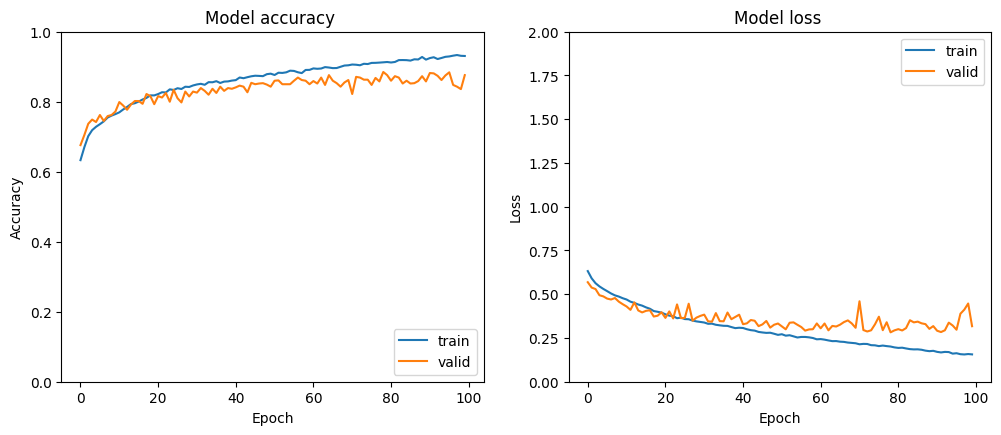

In [13]:
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt

# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(12,10))
# Divide la figura en una cuadrícula y selecciona en qué posición dibujar
plt.subplot(2,2,1)
plt.plot(history_CNN.history['accuracy'])
plt.plot(history_CNN.history['val_accuracy'])
plt.ylim(0, 1)
# Agrega un título al gráfico o imagen mostrada
plt.title('Model accuracy ')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['train', 'valid'], loc='lower right')
plt.subplot(2,2,2)
plt.plot(history_CNN.history['loss'])
plt.plot(history_CNN.history['val_loss'])
plt.title('Model loss ')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'valid'], loc='upper right')
plt.ylim([0,2])

In [14]:
# Guarda el modelo entrenado (su arquitectura y pesos aprendidos) en un archivo .keras para reutilizarlo sin re-entrenar
model.save('modelo_CNN_complejo_muestra_5000_epocas_100.keras')

# Matriz de confusión

In [15]:
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
# Pandas: librería para trabajar con tablas de datos
import pandas as pd
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2 as cv
from numpy import random
# 'glob' permite buscar archivos que cumplan un patrón (ej: todas las imágenes .jpg de una carpeta)
import glob
from numpy import load

import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [16]:
!ls

Creacion_dataset_muestra.ipynb
data_2000train_200val_240test
data_5000train_500val_240test
data_raw
Descarga_Datos_Kaggle.ipynb
mejor_modelo_conservador.keras
modelo_CNN_2.keras
modelo_CNN_3.keras
modelo_CNN_4.keras
modelo_CNN_complejo_muestra_5000_epocas_100.keras
modelo_CNN_complejo_muestra_5000.keras
Parte_0_Generación_X_y.ipynb
Parte_1A_Modelo_CNN_AUG2.ipynb
Parte_1A_Modelo_CNN_AUG.ipynb
Parte_1_Modelos_CNN_complejo_Dataset_5000.ipynb
Parte_1_Modelos_CNN_complejo.ipynb
Parte2_prediccion_MatrizConfusion.ipynb


In [17]:
# Cargar los datos
X_test = load('data_5000train_500val_240test/test/X_test.npy')
y_test = load('data_5000train_500val_240test/test/y_test.npy')

print(X_test.shape)
print(y_test.shape)

(480, 220, 220, 3)
(480,)


In [18]:
##
import tensorflow as tf
X_test= tf.image.resize(X_test, (220, 220))

# Escalar los datos
X_test_scaled = X_test / 255

#  Predicciones sobre los datos de test
# Usa el modelo entrenado para generar predicciones sobre nuevas imágenes
y_pred = model.predict(X_test_scaled)

# Convertir las predicciones (one-hot) a etiquetas de clase
y_pred_classes = (y_pred > 0.5).astype(int).flatten()
y_true_classes = y_test # Assuming y_test_oct is already in class labels
y_true_classes

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

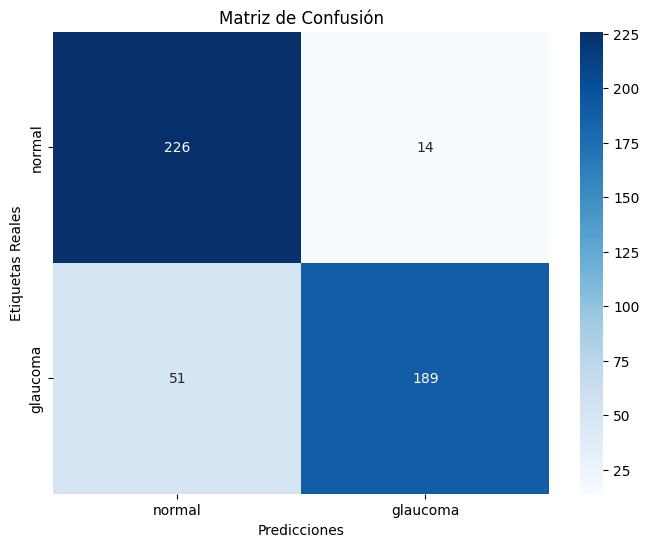

In [19]:
# Convertir los índices a las etiquetas correspondientes usando el diccionario
# Diccionario que traduce el nombre de la clase (texto) a un número (0 = normal, 1 = glaucoma) que el modelo pueda usar
labels_dict = {'normal': 0, 'glaucoma': 1}
labels = list(labels_dict.keys())

#  Calcular la matriz de confusión
# Calcula la matriz de confusión: compara las predicciones del modelo contra las etiquetas reales
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Display the confusion matrix using a heatmap
# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(8, 6))
# Dibuja la matriz de confusión como un mapa de calor, más fácil de leer visualmente
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
# Agrega un título al gráfico o imagen mostrada
plt.title('Matriz de Confusión')
plt.xlabel('Predicciones')
plt.ylabel('Etiquetas Reales')
# Renderiza (dibuja) el gráfico en pantalla
plt.show()

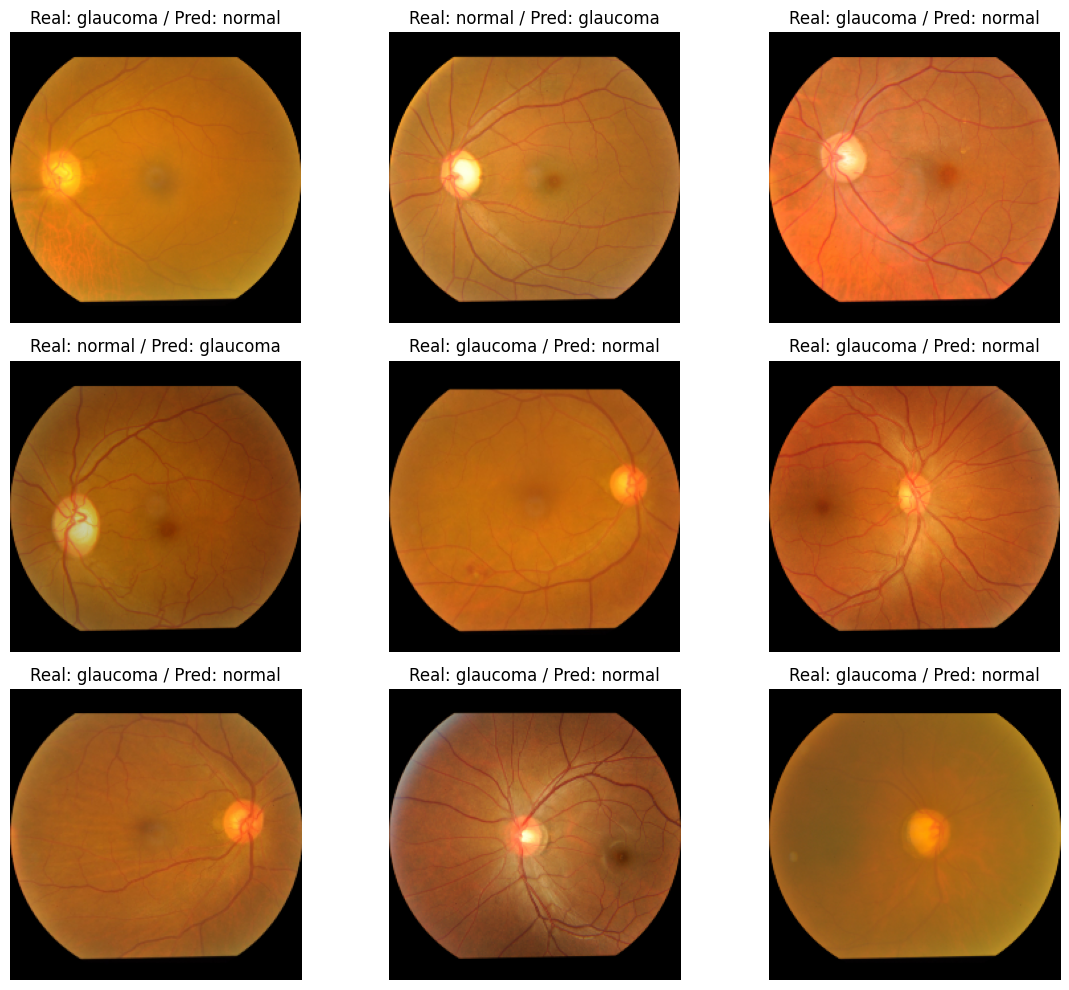

In [20]:
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2

# Encontrar índices de ejemplos mal clasificados
misclassified_indices = np.where(y_pred_classes != y_true_classes)[0]

# Seleccionar aleatoriamente algunos índices mal clasificados
num_ejemplos = min(9, len(misclassified_indices))  # Mostrar hasta 9
random_misclassified_indices = np.random.choice(misclassified_indices, size=num_ejemplos, replace=False)


# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(12, 10))

for i, idx in enumerate(random_misclassified_indices):
    img = X_test[idx].numpy().astype("uint8")  # Imagen original sin escalar
    # OpenCV lee las imágenes en formato de color BGR; esto las convierte a RGB, que es el formato correcto para mostrarlas con matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convertir a RGB
    true_label = labels[y_true_classes[idx]]
    pred_label = labels[y_pred_classes[idx]]

    # Divide la figura en una cuadrícula y selecciona en qué posición dibujar
    plt.subplot(3, 3, i + 1)
    # Muestra una imagen en pantalla
    plt.imshow(img_rgb)
    # Agrega un título al gráfico o imagen mostrada
    plt.title(f'Real: {true_label} / Pred: {pred_label}')
    # Oculta o ajusta los ejes del gráfico (por estética)
    plt.axis('off')

plt.tight_layout()
# Renderiza (dibuja) el gráfico en pantalla
plt.show()